
  # Laboratorio 1 — Implementando un Algoritmo Genético para Optimizar  una Parábola

  **Materia:** Inteligencia Artificial — FP-UNA
  **Profesor:** Christian von Lücken
  **Alumno:** David Gómez

  **Objetivo:** encontrar los parámetros `(a, b, c)` de la parábola `y =
  a·x² + b·x + c`
  que produzcan la curva **más plana posible hacia arriba** (`a > 0`),
  usando un
  algoritmo genético implementado desde cero.

 ## Parte 1 — Lectura y comprensión teórica


 ### 1.1 ¿Qué es un algoritmo genético y en qué se inspira?
 

Un algoritmo genético (GA) es una **metaheurística de búsqueda y optimización, poblacional y estocástica**: resuelve un problema haciendo evolucionar un conjunto de soluciones candidatas, en lugar de construir una única solución paso a paso. Pertenece a la familia de las heurísticas tal como se las definió en clase, o sea técnicas que buscan soluciones buenas(pero que pueden no ser las mejores) a un costo computacional razonable, sin garantizar factibilidad ni optimalidad, pero no pueden dererminar qué tan cerca quedo el resultado del valor optimo. Fue desarrollado por **John H. Holland** a principios de la década de 1960 con el nombre de "planes reproductivos y adaptativos", en un intento por hacer que las computadoras aprendieran imitando el proceso de la evolución.

Su funcionamiento es un ciclo que se repite: se parte de una población inicial de soluciones codificadas, se le asigna a cada una un valor de aptitud (*fitness*) que mide su calidad, y se construye la generación siguiente aplicando selección, cruzamiento y mutación. Al repetir el ciclo, la aptitud de la población tiende a mejorar.

La inspiración es el **neo-darwinismo**, que explica toda la vida en el planeta mediante cuatro procesos: **reproducción, mutación, competencia y selección**. Un algoritmo genético es, literalmente, una simulación computacional de esos cuatro procesos. La referencia de fondo es Darwin (1858): la evolución se origina por cambios aleatorios en características hereditarias combinados con un proceso de selección natural. La distinción con Lamarck es importante y no es un detalle histórico: el individuo no mejora durante su vida para después transmitir esa mejora, sino que la variación aparece **al azar** y es la selección la que la filtra. Por eso en un GA la mutación es ciega al objetivo y toda la presión hacia la mejora la ejerce la selección.

De la biología se toma también el vocabulario: el **cromosoma** (o individuo) es una solución candidata codificada; el **gen** es cada una de sus componentes; el **alelo**, el conjunto de valores que un gen puede tomar; el **genotipo** es la solución codificada y el **fenotipo**, la solución ya decodificada en el dominio del problema. En este laboratorio el individuo es la terna `(a, b, c)` con los coeficientes de la parábola.

### 1.2 Población, función de fitness, selección, crossover y mutación

**Población.** Conjunto de soluciones candidatas que el algoritmo mantiene y hace evolucionar en paralelo. Que sean varias a la vez es lo que distingue a un GA de una búsqueda local, y lo que le permite muestrear distintas regiones del espacio al mismo tiempo.
*En este laboratorio:* `population_size` ternas `(a, b, c)` de números reales, generadas al azar con `random.uniform(lower_bound, upper_bound)` dentro del rango `[-50, 50]`. La codificación es directa en punto flotante y no binaria, así que acá el genotipo coincide con el fenotipo.

**Función de fitness (aptitud).** Asigna a cada individuo un número que mide qué tan buena es la solución que representa. Es el único componente que depende del problema: todo el resto del algoritmo es genérico.
*En este laboratorio:* mide qué tan plana es la parábola. Calcula el vértice en `x = -b/(2a)`, evalúa cuánto sube la curva desde el vértice hasta `x = -1` y hasta `x = 1`, suma esas dos subidas (`curviness`) y devuelve el valor **negado**, porque el GA maximiza y lo que se busca es minimizar la curvatura. Si `a <= 0` devuelve `-inf`, descartando de entrada las parábolas que abren hacia abajo. Nótese que `c` no influye en el resultado: desplazar la parábola verticalmente no la hace más ni menos plana.

**Selección.** Decide qué individuos se reproducen, dando más probabilidad a los de mejor aptitud. La intensidad de ese sesgo es la **presión selectiva**: mucha presión acelera la convergencia pero aumenta el riesgo de convergencia prematura; poca presión hace que el algoritmo casi no progrese.
*En este laboratorio:* selección por **torneo de tamaño 3** — se toman tres individuos al azar y pasa el de mejor fitness, repitiendo hasta completar la población. La alternativa clásica es la **ruleta**, donde la probabilidad de ser elegido es proporcional al fitness.

**Crossover (cruzamiento).** Combina el material genético de dos padres para producir hijos. Es el mecanismo de **explotación**: no crea material nuevo, recombina el que ya está presente en la población.
*En este laboratorio:* cruzamiento **aritmético**. Se sortea un `alpha` en `[0, 1)` y los hijos resultan de las combinaciones `alpha·p1 + (1-alpha)·p2` y `alpha·p2 + (1-alpha)·p1`. Cada hijo cae sobre el segmento que une a los dos padres, lo que explica por qué la población tiende a contraerse si no interviene la mutación.

**Mutación.** Altera genes al azar con cierta probabilidad. Es el mecanismo de **exploración** o diversificación: es la única fuente de material genético verdaderamente nuevo y, por lo tanto, lo único capaz de sacar a la población de una región donde quedó estancada.
*En este laboratorio:* cada gen se modifica con probabilidad `mutation_rate` sumándole un valor uniforme en `[-1, 1]`, y a continuación se lo recorta para que no se salga de `[lower_bound, upper_bound]`.

A estos cinco componentes el código del tutorial le agrega **elitismo**: el mejor individuo de cada generación se copia sin modificaciones a la generación siguiente, de manera que la mejor solución encontrada nunca se pierde.

### 1.3 ¿Por qué se usa un algoritmo genético para resolver problemas de optimización?

Existen técnicas clásicas muy eficaces cuando el problema tiene la estructura adecuada: el método Simplex para optimización lineal, el gradiente conjugado para la no lineal, la programación dinámica o *branch & bound* para construir soluciones parcialmente. Un algoritmo genético no compite con ellas en ese terreno; se recurre a él justamente cuando esas condiciones no se cumplen.

Un problema se vuelve difícil, en el sentido visto en clase, cuando el número de soluciones posibles es tan grande que una búsqueda exhaustiva resulta inviable el caso típico es el problema del viajante, donde con 50 ciudades hay del orden de 10²⁵ recorridos posibles, cuando la función de evaluación es ruidosa o varía con el tiempo, lo que obliga a trabajar con un conjunto de soluciones en lugar de una sola, o cuando las restricciones son tantas que incluso construir una solución factible es complicado.

En esas condiciones un GA aporta tres ventajas concretas:

- **No necesita derivadas** ni que la función objetivo sea continua o diferenciable. Alcanza con poder evaluarla, es decir, sirve para optimización de caja negra.
- **Trabaja con una población**, de modo que muestrea varias regiones del espacio simultáneamente. Eso lo hace menos propenso a quedar atrapado en un óptimo local que una búsqueda que avanza siguiendo una única solución.
- **Es independiente del dominio.** Lo único específico del problema son la codificación y la función de fitness; el resto —selección, cruzamiento, mutación— es idéntico para una parábola que para el problema del viajante.

La contrapartida es que un GA es una heurística: entrega soluciones buenas a un costo computacional razonable, pero no garantiza alcanzar el óptimo global ni permite saber, en general, a qué distancia del óptimo quedó. Este laboratorio lo ilustra con claridad: la curvatura se minimiza cuando `a` tiende a cero por derecha y `b` tiende a cero, es decir sobre el borde de la región factible (`a > 0`), de modo que el algoritmo puede acercarse indefinidamente pero nunca llegar exactamente.

## Parte 2 — Implementación guiada

In [104]:
import random
import numpy as np
import matplotlib.pyplot as plt
from prettytable import PrettyTable

random.seed(42) # misma semilla para que podamos tener los mismos resultados y evaluar el resultado

In [105]:
def create_initial_population(size, lower_bound, upper_bound):
    population = []
    for _ in range(size):
        individual = (random.uniform(lower_bound, upper_bound), 
                      random.uniform(lower_bound, upper_bound),
                      random.uniform(lower_bound, upper_bound)
                      )
        population.append(individual)
    return population

In [106]:
def fitness_function(params):
    a, b, c = params
    if a <= 0:
        return -float('inf') # penalizamos las parabolas que se abren hacia abajo

    vertexX = -b / (2 * a)
    vertexY = a * vertexX**2 + b *vertexX + c

    yLeft = a * (-1) ** 2 + b * (-1) + c # y en x = -1
    yRight = a * (1) ** 2 + b * (1) + c # y en x = 1

    curviness = abs(yLeft - vertexY) + abs(yRight - vertexY) 
    return -curviness

In [107]:
population = create_initial_population(5, -50, 50)
for ind in population:
    print(ind)

for p in [(0.5, 0, 3), (0.5, 0, -40), (2, 3, 1), (0.1, 0, 0), (5, 0, 0), (-0.5, 0, 3), (0,1, 1)]:
    print(p, "->", fitness_function(p))

(13.942679845788376, -47.498924477733304, -22.497068163088073)
(-27.678926185117724, 23.647121416401234, 17.669948742291126)
(39.217956770484534, -41.30611673705839, -7.807818031472955)
(-47.020278056192964, -28.136202519639664, 0.5355288103362383)
(-47.34640303161364, -30.11623493133515, 14.988443777952327)
(0.5, 0, 3) -> -1.0
(0.5, 0, -40) -> -1.0
(2, 3, 1) -> -6.25
(0.1, 0, 0) -> -0.2
(5, 0, 0) -> -10.0
(-0.5, 0, 3) -> -inf
(0, 1, 1) -> -inf


In [108]:
def selection(population, fitnesses, tournament_size=3):
    selected = []
    for _ in range(len(population)):
        tournament = random.sample(list(zip(population, fitnesses)), tournament_size)
        winner = max(tournament, key=lambda x: x[1] )[0]
        selected.append(winner)
    return selected


In [109]:
selectioned = selection(population, [fitness_function(p) for p in population])
for ind in selectioned:
    print(ind, "->", fitness_function(ind))

(13.942679845788376, -47.498924477733304, -22.497068163088073) -> -108.79332901653116
(39.217956770484534, -41.30611673705839, -7.807818031472955) -> -100.18864392772366
(-27.678926185117724, 23.647121416401234, 17.669948742291126) -> -inf
(39.217956770484534, -41.30611673705839, -7.807818031472955) -> -100.18864392772366
(39.217956770484534, -41.30611673705839, -7.807818031472955) -> -100.18864392772366


In [110]:
def crossover(parent1, parent2): # el cruzamiento
    alpha = random.random()
    child1 = tuple(alpha * p1 + (1 - alpha) * p2 for p1, p2 in zip(parent1, parent2))
    child2 = tuple(alpha * p2 + (1 - alpha) * p1 for p1, p2 in zip(parent1, parent2))
    return child1, child2

def mutation(individual, mutation_rate, lower_bound, upper_bound):
    individual = list(individual)
    for i in range(len(individual)):
        if random.random() < mutation_rate:
            mutation_amount = random.uniform(-1, 1)
            individual[i] += mutation_amount
            individual[i] = max(min(individual[i], upper_bound), lower_bound)
    return tuple(individual)


In [111]:
for parent1, parent2 in zip(selectioned[::2], selectioned[1::2]):
    child1, child2 = crossover(parent1, parent2)
    print("Parents:", parent1, parent2)
    print("Children:", child1, child2)
    print("mutated Children:", mutation(child1, 0.1, -50, 50), mutation(child2, 0.1, -50, 50))
    print()

Parents: (13.942679845788376, -47.498924477733304, -22.497068163088073) (39.217956770484534, -41.30611673705839, -7.807818031472955)
Children: (29.61518903562354, -43.65893346533902, -13.38866518236414) (23.54544758064937, -45.146107749452675, -16.91622101219689)
mutated Children: (29.61518903562354, -43.65893346533902, -13.38866518236414) (23.464297339993056, -45.146107749452675, -16.91622101219689)

Parents: (-27.678926185117724, 23.647121416401234, 17.669948742291126) (39.217956770484534, -41.30611673705839, -7.807818031472955)
Children: (33.946469142751646, -36.187788704728504, -5.800164963103585) (-22.407438557384836, 18.52879338407135, 15.662295673921758)
mutated Children: (33.946469142751646, -36.187788704728504, -5.800164963103585) (-22.407438557384836, 18.52879338407135, 15.984822311057178)



In [112]:
def genetic_algorithm(population_size, lower_bound, upper_bound, generations, mutation_rate):
    population = create_initial_population(population_size, lower_bound, upper_bound)
    
    best_performers = [] # mejor individio por cada gneracion
    all_populations = [] # snapshot de todas las generaciones

    table = PrettyTable()
    table.field_names = ["Generation", "a", "b", "c", "Fitness"]

    for generation in range(generations):
        fitnesses = [fitness_function(ind) for ind in population]

        best_individual = max(population, key=fitness_function)
        best_fitness = fitness_function(best_individual)
        best_performers.append((best_individual, best_fitness))
        all_populations.append(population[:])
        table.add_row([generation + 1, best_individual[0], best_individual[1], best_individual[2], best_fitness])

        population = selection(population, fitnesses)

        next_population = []
        for i in range(0, len(population), 2):
            child1, child2 = crossover(population[i], population[i + 1])
            next_population.append(mutation(child1, mutation_rate, lower_bound, upper_bound))
            next_population.append(mutation(child2, mutation_rate, lower_bound, upper_bound))

        next_population[0] = best_individual
        population = next_population

    print(table)
    return max(population, key=fitness_function), best_performers, all_populations


In [113]:
population_size = 100
lower_bound = -50
upper_bound = 50
generations = 20
mutation_rate = 1

random.seed(42)
best_solution, best_performers, all_populations = genetic_algorithm(
    population_size, lower_bound, upper_bound, generations, mutation_rate
)

print(f"\nMejor solución: a = {best_solution[0]}, b = {best_solution[1]}, c = {best_solution[2]}")


+------------+---------------------+-----------------------+--------------------+----------------------+
| Generation |          a          |           b           |         c          |       Fitness        |
+------------+---------------------+-----------------------+--------------------+----------------------+
|     1      |  7.1043093325284445 |  -2.7328973688205878  | 28.461942429075336 |  -14.73426638666647  |
|     2      |  7.1043093325284445 |  -2.7328973688205878  | 28.461942429075336 |  -14.73426638666647  |
|     3      |  4.872578589027569  |  -4.6020073034288025  | 3.1526782780483504 | -11.918387515324945  |
|     4      |  4.872578589027569  |  -4.6020073034288025  | 3.1526782780483504 | -11.918387515324945  |
|     5      |  4.872578589027569  |  -4.6020073034288025  | 3.1526782780483504 | -11.918387515324945  |
|     6      |  4.474998141528115  |  -4.9923390990109295  | 2.9343608928326255 |  -11.7347404205144   |
|     7      |  4.129848073535627  |   -3.6066400416307

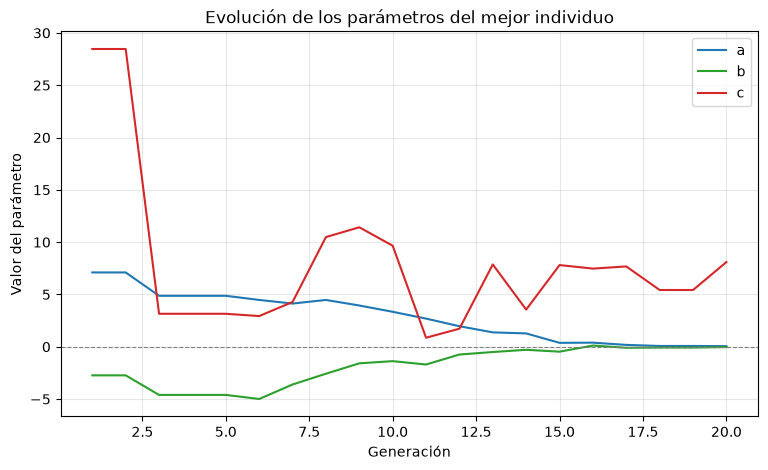

In [114]:
generations_list = list(range(1, len(best_performers) + 1))
a_values = [ind[0][0] for ind in best_performers ]
b_values = [ind[0][1] for ind in best_performers ]
c_values = [ind[0][2] for ind in best_performers ]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(generations_list, a_values, label='a', color='tab:blue')
ax.plot(generations_list, b_values, label='b', color='tab:green')
ax.plot(generations_list, c_values, label='c', color='tab:red')
ax.axhline(0, color='gray', lw=0.8, ls='--')
ax.set_xlabel('Generación')
ax.set_ylabel('Valor del parámetro')
ax.set_title('Evolución de los parámetros del mejor individuo')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

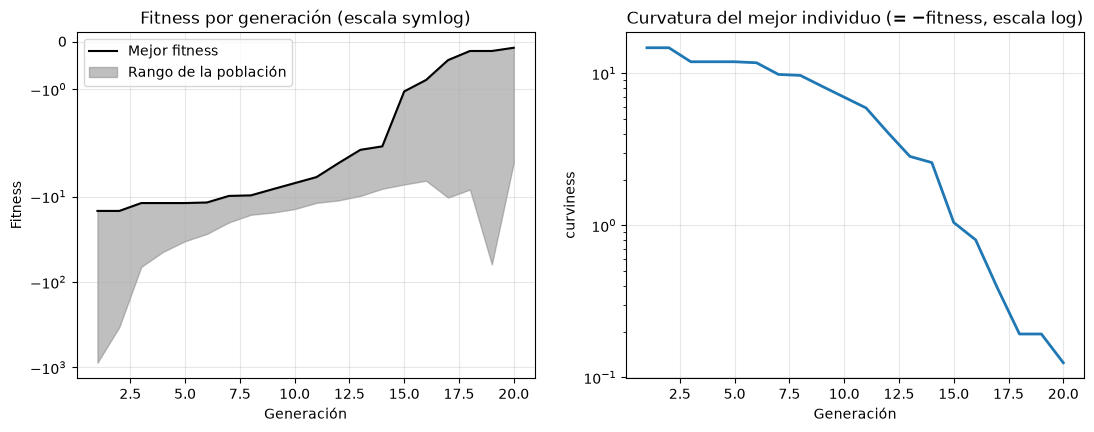

In [115]:
best_fitness_values = [fit[1] for fit in best_performers]

min_fitness_values, max_fitness_values = [], []
for pop in all_populations:
    finites = [f for f in map(fitness_function, pop) if f != -float('inf')]
    min_fitness_values.append(min(finites) if finites else float('nan'))
    max_fitness_values.append(max(finites) if finites else float('nan'))

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
axs[0].plot(generations_list, best_fitness_values, label='Mejor fitness', color='black')
axs[0].fill_between(generations_list, min_fitness_values, max_fitness_values,
                    color='gray', alpha=0.5, label='Rango de la población')
axs[0].set_yscale('symlog')
axs[0].set_xlabel('Generación'); axs[0].set_ylabel('Fitness')
axs[0].set_title('Fitness por generación (escala symlog)')
axs[0].legend(); axs[0].grid(alpha=0.3)

axs[1].semilogy(generations_list, [-f for f in best_fitness_values], color='tab:blue', lw=2)
axs[1].set_xlabel('Generación'); axs[1].set_ylabel('curviness')
axs[1].set_title('Curvatura del mejor individuo (= −fitness, escala log)')
axs[1].grid(alpha=0.3)

plt.show()


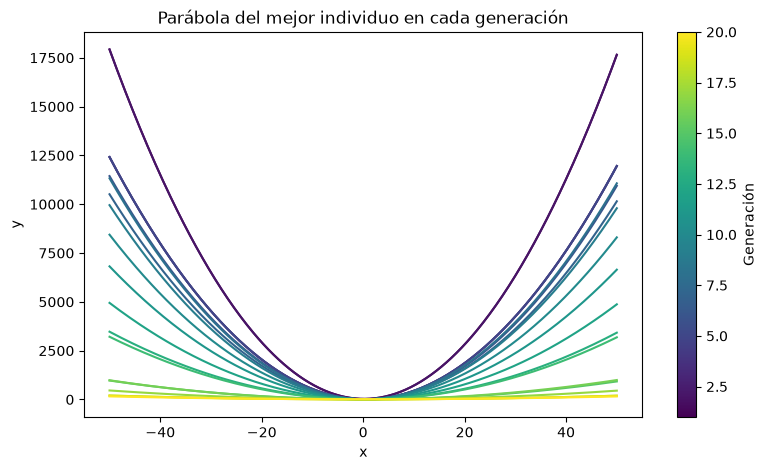

In [116]:
fig, ax = plt.subplots(figsize=(9, 5))
colors = plt.cm.viridis(np.linspace(0, 1, len(best_performers)))
x_range = np.linspace(lower_bound, upper_bound, 400)

for i, (best_ind, best_fit) in enumerate(best_performers):
    a, b, c = best_ind
    ax.plot(x_range, a * x_range**2 + b * x_range + c, color=colors[i])

sm = plt.cm.ScalarMappable(cmap='viridis',
                            norm=plt.Normalize(1, len(best_performers)))
sm.set_array([])
fig.colorbar(sm, ax=ax, label='Generación')
ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_title('Parábola del mejor individuo en cada generación')
plt.show()

### Pregunta de reflexión

> **¿Qué significa que el algoritmo "encuentre" valores de a ≈ 0 (pero positivo), b ≈ 0 y c cualquiera? ¿Por qué penaliza a ≤ 0 en la función de fitness?**

Las tres observaciones se explican con un único hecho algebraico. La función de fitness evalúa la parábola en el vértice y en `x = ±1`, y suma las dos diferencias en valor absoluto. Al desarrollar esas restas, la expresión se simplifica por completo:

```
vértice:        y_v = c − b²/(4a)

y(−1) − y_v  =  a − b + b²/(4a)  =  (2a − b)² / (4a)
y(+1) − y_v  =  a + b + b²/(4a)  =  (2a + b)² / (4a)

curviness    =  [(2a − b)² + (2a + b)²] / (4a)  =  (8a² + 2b²) / (4a)
```

es decir:

```
curviness = 2·|a| + b²/(2·|a|)            fitness = −curviness
```

Toda la respuesta está contenida en esa expresión.

#### a ≈ 0 pero positivo

Con `b = 0` la curvatura se reduce a `2a`, que decrece de forma monótona a medida que `a` se achica. **No existe un mínimo**: el ínfimo es 0 y no se alcanza, porque `a = 0` está excluido del dominio. Que el algoritmo "encuentre" `a ≈ 0` positivo significa, entonces, que convergió al **borde de la región factible**, y que el óptimo es un límite antes que un punto alcanzable. Geométricamente se le está pidiendo aproximar una parábola degenerada: la curva más plana que abre hacia arriba es, en el límite, una recta horizontal.

Esto tiene una consecuencia práctica comprobable: el algoritmo nunca termina de converger. Repitiendo la misma corrida con más generaciones, `a` sigue bajando indefinidamente (ver la celda siguiente).

#### b ≈ 0

El término `b²/(2·|a|)` penaliza que el vértice esté desplazado respecto de `x = 0`. Con `b ≠ 0` el vértice se ubica en `x = −b/(2a)` y la parábola sube más de un lado que del otro dentro del intervalo `[−1, 1]`, que es justamente donde se mide la planitud.

Dos detalles de ese término importan. `b` entra al cuadrado, así que el castigo es simétrico respecto de su signo; y está **dividido por `a`**, de modo que se vuelve más severo a medida que `a` se achica. La presión selectiva sobre `b` se intensifica sola a lo largo de la corrida. Los resultados lo confirman: a las 50 generaciones el término de `a` aporta el 91 % de la curvatura y el de `b` apenas el 9 %, mientras que a las 200 generaciones la proporción se invierte y `b` pasa a aportar el 64 %. Seguir achicando `a` deja de rendir si `b` no lo acompaña.

#### c cualquiera

`c` no aparece en la expresión: se cancela al restar. No es una casualidad algebraica sino el reflejo de un hecho geométrico — `c` desplaza la parábola entera verticalmente, vértice incluido, y la planitud es una propiedad de la **forma** de la curva, no de su posición.

En términos del algoritmo, el paisaje de fitness es perfectamente **plano** a lo largo del eje `c`, de modo que la selección no ejerce ninguna presión en esa dirección. `c` es un **gen neutro**: su valor final no es producto de la optimización sino del arrastre aleatorio del cruzamiento y la mutación. Cualquier valor de `c` es igualmente óptimo, y eso es exactamente lo que muestra la gráfica de las parábolas: las curvas de las últimas generaciones son todas igual de planas, pero están a distintas alturas.

#### Por qué se penaliza a ≤ 0

Hay dos razones, de naturaleza distinta.

**La primera es de definición.** Con `a = 0` la expresión `x_v = −b/(2a)` divide por cero, y además la función deja de ser una parábola: es una recta. Por eso la guarda es `a <= 0` y no `a < 0`.

**La segunda** Como la función toma valores absolutos, el resultado depende de `|a|` y no de `a`. Una parábola con `a = −0.001` obtiene **exactamente el mismo fitness** que una con `a = +0.001`. Sin la penalización, el algoritmo sería por completo indiferente entre una curva que abre hacia arriba y su reflejo que abre hacia abajo, y aproximadamente la mitad de las soluciones finales quedarían invertidas, lo que no cumple con lo que se dice en el enunciado que la parabola sea plana **hacia arriba**.

La penalización no es una formalidad ni el manejo de un caso de borde: es el único mecanismo que rompe esa simetría y convierte "la parábola más plana" en "la parábola más plana que abre hacia arriba". La forma concreta de implementarla devolver `-inf` es discutible y se retoma en la Parte 4.

#### Evidencia en los resultados obtenidos

| Afirmación | Evidencia en esta corrida |
|---|---|
| `a → 0⁺` | 7.1043 en la generación 1, 0.0592 en la 20 |
| `b → 0` | −2.7329 en la generación 1, −0.0276 en la 20 |
| `c` no converge | 28.46 → 3.15 → 11.42 → 0.87 → 7.87 → 8.10, sin dirección |
| `c` es libre, no indefinido | las curvas finales de la tercera gráfica son planas pero están a distinta altura |
| el óptimo nunca se alcanza | celda siguiente: 20, 50 y 200 generaciones |

In [ ]:
# ¿El algoritmo converge a un punto, o se acerca indefinidamente al borde a = 0?
import io, contextlib

for n_gen in (20, 50, 200):
    random.seed(42)
    with contextlib.redirect_stdout(io.StringIO()):      # silencia la tabla de PrettyTable
        _, bp, _ = genetic_algorithm(population_size, lower_bound, upper_bound,
                                     n_gen, mutation_rate)
    ind, fit = bp[-1]
    aporte_a = 2 * abs(ind[0])
    aporte_b = ind[1] ** 2 / (2 * abs(ind[0]))
    total = aporte_a + aporte_b
    print(f"{n_gen:>4} gen -> a = {ind[0]:.8f}   b = {ind[1]:>12.8f}   fitness = {fit:.8f}"
          f"   | curvatura: {aporte_a/total:>4.0%} por a, {aporte_b/total:>4.0%} por b")